# Poker Decision Lab: research notebook

This notebook uses the project's engine (`pokerlab`) to answer four questions about
the call/fold model. Every number is computed live by the same code the app runs.

1. **Is the simulation trustworthy?** Monte Carlo convergence and confidence-interval coverage.
2. **How much do the assumptions matter?** The same decision under 9 opponent models.
3. **Pot odds in practice:** how much equity a call needs, and which hands have it.
4. **Equity realisation:** who gains and who loses when betting continues on later streets.

The mathematics is written up in [`docs/math.md`](../docs/math.md).
Run it yourself with `uv sync --group notebook` and open it in Jupyter or VS Code.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

from pokerlab.cards import card_to_pretty, parse_cards, remaining_deck
from pokerlab.decision import Situation
from pokerlab.equity import exact_equity, monte_carlo_equity
from pokerlab.evaluator import Category, category_of, evaluate
from pokerlab.multistreet import analyse_call
from pokerlab.profiles import PROFILES
from pokerlab.spot import Spot

# Chart style: light surface, thin marks, recessive axes, fixed categorical order.
BLUE, ORANGE, AQUA, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c9c8c2",
        "axes.labelcolor": INK_2,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#ebeae6",
        "grid.linewidth": 0.8,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def pretty(cards: str) -> str:
    return " ".join(card_to_pretty(c) for c in parse_cards(cards))

## 1. Is the simulation trustworthy?

The example spot: **A♠Q♠ on J♠ 8♦ 4♠ against the Tight range**. On the flop the exact
answer is cheap (every opponent hand × every turn and river card), so we can grade the
Monte Carlo estimator against the truth.

**Convergence.** One simulation per sample size, each with a 95% confidence interval.
The interval should shrink like $1/\sqrt{n}$ and contain the exact value about 19 times
out of 20 (so the occasional miss, like the 500-deal run here, is expected).

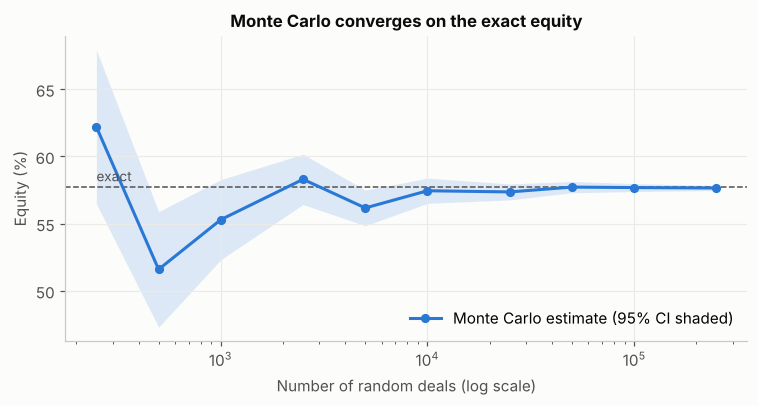

Exact equity: 57.7639% (90,090 showdowns enumerated)
n =     250: 62.200% ± 5.721%   error vs exact +4.436%
n =     500: 51.600% ± 4.296%   error vs exact -6.164%
n =   1,000: 55.300% ± 2.975%   error vs exact -2.464%
n =   2,500: 58.300% ± 1.871%   error vs exact +0.536%
n =   5,000: 56.170% ± 1.324%   error vs exact -1.594%
n =  10,000: 57.450% ± 0.936%   error vs exact -0.314%
n =  25,000: 57.362% ± 0.592%   error vs exact -0.402%
n =  50,000: 57.721% ± 0.418%   error vs exact -0.043%
n = 100,000: 57.686% ± 0.296%   error vs exact -0.078%
n = 250,000: 57.652% ± 0.187%   error vs exact -0.112%


In [2]:
spot = Spot.from_strings("AsQs", "Js8d4s")
tight = PROFILES["tight"].range
truth = exact_equity(spot, tight)
print(f"Exact equity: {truth.equity:.4%} ({truth.estimate.n:,} showdowns enumerated)")

sizes = [250, 500, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
runs = [monte_carlo_equity(spot, tight, samples=n, seed=2026 + i) for i, n in enumerate(sizes)]
est = np.array([r.equity for r in runs])
lo = np.array([r.ci95[0] for r in runs])
hi = np.array([r.ci95[1] for r in runs])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhline(100 * truth.equity, color=INK_2, linewidth=1, linestyle="--")
ax.text(sizes[0], 100 * truth.equity + 0.15, "exact", color=INK_2, fontsize=9, va="bottom")
ax.fill_between(sizes, 100 * lo, 100 * hi, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(
    sizes,
    100 * est,
    color=BLUE,
    marker="o",
    markersize=5,
    label="Monte Carlo estimate (95% CI shaded)",
)
ax.set_xscale("log")
ax.set_xlabel("Number of random deals (log scale)")
ax.set_ylabel("Equity (%)")
ax.set_title("Monte Carlo converges on the exact equity")
ax.legend(loc="lower right")
plt.show()

for n, r in zip(sizes, runs, strict=False):
    half = (r.ci95[1] - r.ci95[0]) / 2
    print(
        f"n = {n:>7,}: {r.equity:.3%} ± {half:.3%}   error vs exact {r.equity - truth.equity:+.3%}"
    )

**Coverage.** A 95% interval should contain the true value in 95% of repeated
experiments, not just usually. We repeat a small simulation (1,000 deals) 400 times
with different seeds and count the misses.

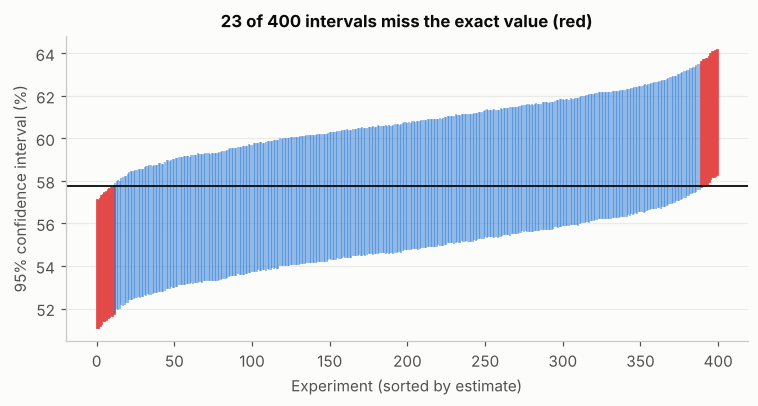

Coverage: 94.2% of 400 intervals contain the exact equity (expected 95%, sampling noise ± 2.1%)


In [3]:
reps, n = 400, 1_000
intervals = np.array([monte_carlo_equity(spot, tight, samples=n, seed=s).ci95 for s in range(reps)])
covered = (intervals[:, 0] <= truth.equity) & (truth.equity <= intervals[:, 1])
rate = covered.mean()
se_rate = np.sqrt(0.95 * 0.05 / reps)
print(
    f"Coverage: {rate:.1%} of {reps} intervals contain the exact equity "
    f"(expected 95%, sampling noise ± {1.96 * se_rate:.1%})"
)

order = np.argsort(intervals.mean(axis=1))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, i in enumerate(order):
    ax.plot(
        [k, k],
        100 * intervals[i],
        color=BLUE if covered[i] else RED,
        linewidth=1.2 if covered[i] else 1.8,
        alpha=0.55 if covered[i] else 1,
    )
ax.axhline(100 * truth.equity, color=INK, linewidth=1.2)
ax.set_xlabel("Experiment (sorted by estimate)")
ax.set_ylabel("95% confidence interval (%)")
ax.set_title(f"{(~covered).sum()} of {reps} intervals miss the exact value (red)")
ax.grid(axis="x", visible=False)
plt.show()

**Takeaway.** The estimator is unbiased, its error shrinks like $1/\sqrt{n}$, and the
intervals have the coverage they claim. With the app's default 50,000 deals the
interval is about ±0.4 percentage points.

## 2. How much do the assumptions matter?

The engine never knows the opponent's cards. It answers *"if the opponent plays like
this, what is the call worth?"*. Here is one decision under all 9 combinations of
**range** (which hands they bet with) and **later-street style** (how they keep betting):

**9♣9♦ on Q♠ J♥ 4♣, pot 100, opponent bets 100, stacks 500.**

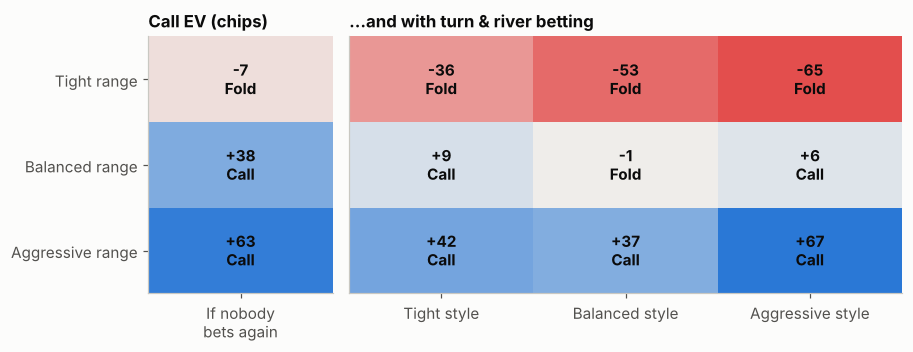

In [4]:
spot = Spot.from_strings("9c9d", "QsJh4c")
sit = Situation(pot=100, bet=100, stack=500)
keys = list(PROFILES)
ev = np.zeros((3, 3))
showdown_ev = np.zeros(3)
for i, rk in enumerate(keys):
    for j, sk in enumerate(keys):
        r = analyse_call(spot, PROFILES[rk].range, sit, PROFILES[sk].strategy)
        ev[i, j] = r.ev_call
    showdown_ev[i] = r.ev_showdown

names = [PROFILES[k].name for k in keys]
cmap = LinearSegmentedColormap.from_list("div", [RED, "#f0efec", BLUE])
limit = np.abs(np.c_[ev, showdown_ev]).max()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(8.4, 3.3), width_ratios=[1, 3])
for ax, data, cols in [
    (ax0, showdown_ev[:, None], ["If nobody\nbets again"]),
    (ax1, ev, [f"{n} style" for n in names]),
]:
    ax.imshow(data, cmap=cmap, vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(3), [f"{n} range" for n in names])
    ax.grid(False)
    for (a, b), v in np.ndenumerate(data):
        ax.text(
            b,
            a,
            f"{v:+.0f}\n{'Call' if v > 0 else 'Fold'}",
            ha="center",
            va="center",
            color=INK,
            fontsize=10,
            fontweight="bold",
        )
ax1.set_yticks([])
ax1.set_title("…and with turn & river betting", loc="left")
ax0.set_title("Call EV (chips)", loc="left")
plt.tight_layout()
plt.show()

**Takeaway.** The same hand is a clear call against a balanced or aggressive range
and a clear fold against a tight one. Later-street betting moves every number by
tens of chips, and in two cells it flips the sign. This is why the app always states
its assumptions next to the verdict, and why a single "correct" answer without a model
of the opponent does not exist.

## 3. Pot odds in practice

Calling $c$ chips into a pot that becomes $P + 2c$ needs equity
$E^{*} = c / (P + 2c)$. Writing the bet as a fraction of the pot, $f = B/P$, this is
$E^{*} = f / (1 + 2f)$: half-pot needs 25%, pot-sized 33%, and no bet ever needs 50%.

Below, the horizontal lines are the showdown equities of five different hands on
**J♠ 8♦ 4♠ against the Balanced range**. Where a hand's line is above the curve, calling is
profitable *if nobody bets again*.

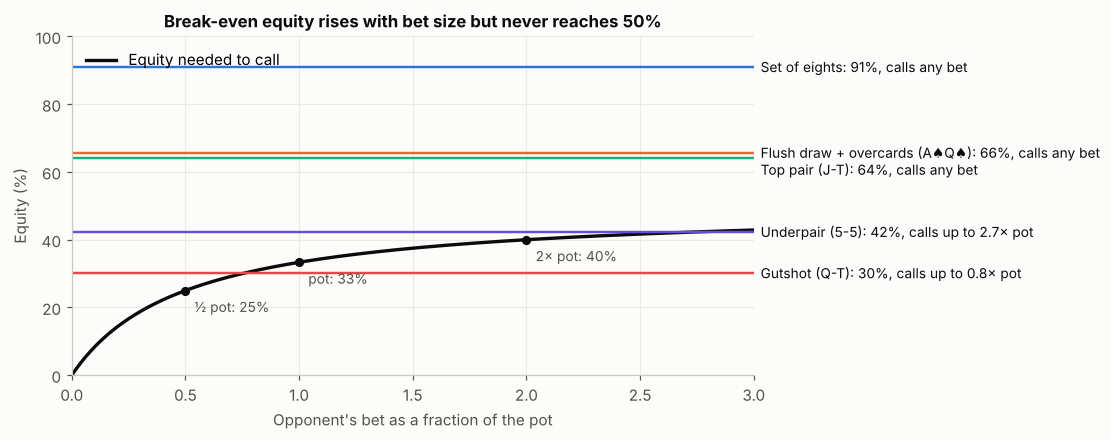

In [5]:
board = "Js8d4s"
balanced = PROFILES["balanced"].range
hands = {
    "Set of eights": "8c8h",
    "Top pair (J-T)": "JhTc",
    "Flush draw + overcards (A♠Q♠)": "AsQs",
    "Gutshot (Q-T)": "QhTd",
    "Underpair (5-5)": "5h5c",
}
equities = {
    name: exact_equity(Spot.from_strings(h, board), balanced).equity for name, h in hands.items()
}

f = np.linspace(0, 3, 301)
need = f / (1 + 2 * f)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f, 100 * need, color=INK, linewidth=2.2, label="Equity needed to call")
colors = [BLUE, ORANGE, AQUA, "#6250d6", RED]
label_y = 101.0
for (name, e), col in zip(sorted(equities.items(), key=lambda x: -x[1]), colors, strict=False):
    ax.axhline(100 * e, color=col, linewidth=1.6)
    max_f = e / (1 - 2 * e) if e < 0.5 else np.inf
    label = f"{name}: {e:.0%}" + (
        f", calls up to {max_f:.1f}× pot" if max_f < 3 else ", calls any bet"
    )
    label_y = min(100 * e, label_y - 5)  # keep labels at least 5 points apart
    ax.text(3.03, label_y, label, color=INK, fontsize=9, va="center")
for x, txt in [(0.5, "½ pot"), (1, "pot"), (2, "2× pot")]:
    ax.plot(x, 100 * x / (1 + 2 * x), "o", color=INK, markersize=5)
    ax.annotate(
        f"{txt}: {x / (1 + 2 * x):.0%}",
        (x, 100 * x / (1 + 2 * x)),
        xytext=(6, -14),
        textcoords="offset points",
        fontsize=9,
        color=INK_2,
    )
ax.set_xlim(0, 3)
ax.set_ylim(0, 100)
ax.set_xlabel("Opponent's bet as a fraction of the pot")
ax.set_ylabel("Equity (%)")
ax.set_title("Break-even equity rises with bet size but never reaches 50%")
ax.legend(loc="upper left")
plt.show()

**Takeaway.** Bet size matters less than intuition suggests: going from a half-pot
to a pot-sized bet only raises the requirement from 25% to 33%. Draws such as a
flush draw with overcards clear even large bets *on equity alone*. Whether they
should call depends on what happens later, which is the next question.

## 4. Equity realisation: who gains from later betting?

Raw equity assumes the cards are simply dealt out. With turn and river betting
(Balanced range and style, pot 100, bet 50, stacks 500), a hand may **realise** more
or less than its raw equity: strong hands win extra bets, while hands that often have
to fold give up pots. Here every possible hero hand on **J♠ 8♦ 4♠** is grouped by what
it has on the flop.

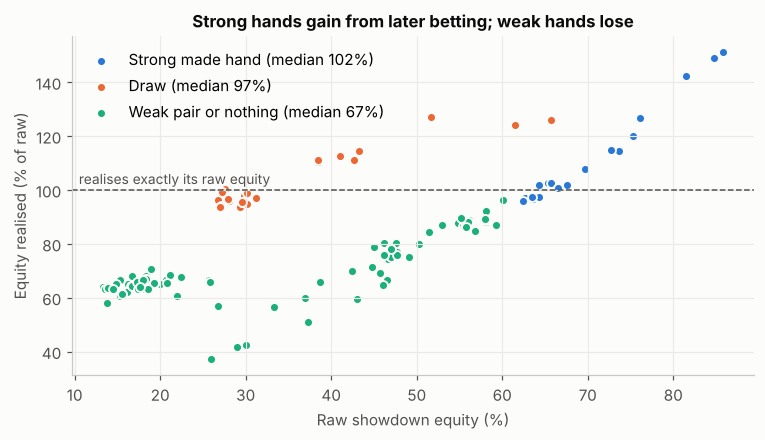

180 hands analysed in 66.0 s
  Strong made hand        22 hands, median realisation 102%
  Draw                    35 hands, median realisation 97%
  Weak pair or nothing   123 hands, median realisation 67%


In [6]:
board_cards = parse_cards("Js8d4s")
sit = Situation(pot=100, bet=50, stack=500)
profile = PROFILES["balanced"]

TOP = max(c // 4 for c in board_cards)  # rank of the highest board card (the jack)


def group(hero):
    cards = [*hero, *board_cards]
    cat = category_of(evaluate(cards))
    ranks = [c // 4 for c in hero]
    top_pair = cat == Category.PAIR and TOP in ranks
    overpair = cat == Category.PAIR and ranks[0] == ranks[1] and ranks[0] > TOP
    if cat >= Category.TWO_PAIR or top_pair or overpair:
        return "Strong made hand"
    suits = [c % 4 for c in cards]
    flush_draw = max(suits.count(s) for s in range(4)) == 4
    straight_draw = cat < Category.STRAIGHT and any(
        category_of(evaluate([*cards, x])) == Category.STRAIGHT for x in remaining_deck(cards)
    )
    if flush_draw or straight_draw:
        return "Draw"
    return "Weak pair or nothing"


rng_gen = np.random.default_rng(1)
deck = remaining_deck(board_cards)
pairs = [(a, b) for i, a in enumerate(deck) for b in deck[i + 1 :]]
sample = [pairs[i] for i in rng_gen.choice(len(pairs), size=180, replace=False)]

start = time.perf_counter()
rows = []
for hero in sample:
    r = analyse_call(Spot(hero, tuple(board_cards)), profile.range, sit, profile.strategy)
    rows.append((group(hero), r.equity, r.realization))
print(f"{len(rows)} hands analysed in {time.perf_counter() - start:.1f} s")
for g in ["Strong made hand", "Draw", "Weak pair or nothing"]:
    z = [zz for gg, _, zz in rows if gg == g]
    print(f"  {g:22s} {len(z):3d} hands, median realisation {np.median(z):.0%}")

groups = ["Strong made hand", "Draw", "Weak pair or nothing"]
fig, ax = plt.subplots(figsize=(8, 4))
for g, col in zip(groups, [BLUE, ORANGE, AQUA], strict=False):
    pts = np.array([(e, z) for gg, e, z in rows if gg == g])
    ax.scatter(
        100 * pts[:, 0],
        100 * pts[:, 1],
        s=34,
        color=col,
        edgecolor="#fcfcfb",
        linewidth=1.2,
        label=f"{g} (median {np.median(pts[:, 1]):.0%})",
    )
ax.axhline(100, color=INK_2, linewidth=1, linestyle="--")
ax.text(
    0.01,
    101,
    "realises exactly its raw equity",
    color=INK_2,
    fontsize=9,
    va="bottom",
    ha="left",
    transform=ax.get_yaxis_transform(),
)
ax.set_xlabel("Raw showdown equity (%)")
ax.set_ylabel("Equity realised (% of raw)")
ax.set_title("Strong hands gain from later betting; weak hands lose")
ax.legend(loc="upper left")
plt.show()

**Takeaway.** Strong made hands (top pair or better) realise about 100% or more of their equity: the opponent keeps
betting weaker hands into them. Weak pairs realise much less, because they must fold
to later bets that are often bluffs. Draws sit in between: they fold when they miss but
collect bets when they hit.

**A caveat about the model.** The hero is assumed to know the opponent's (simple,
fixed) strategy and to respond perfectly. A real opponent adapts, so these realisation
figures, especially the large gains, are optimistic. That is the main reason the app
always shows both numbers: the showdown-only EV and the EV with later betting.

## Summary

- The simulation is verified: unbiased estimates and 95% intervals that really cover 95%.
- **The opponent model drives the decision.** The same hand flips between call and fold across plausible ranges and styles.
- Pot odds change slowly with bet size; what decides marginal calls is the range assumption and later-street play.
- Later betting redistributes value: strong hands gain, weak hands lose.